# Support Vector Machine (SVM) on Iris Dataset

In this lab, we implement **Support Vector Machine (SVM)** for classification on the Iris dataset.

#### Mathematical Foundation:
1. **Maximal Margin Hyperplane**:
   $$\min_{\mathbf{w}, b} \frac{1}{2} \|\mathbf{w}\|^2 \quad \text{subject to} \quad y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \ge 1$$
2. **Radial Basis Function (RBF) Kernel**:
   $$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2\right)$$

### 1. Importing the necessary modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### 2. Loading the built-in Iris dataset directly from scikit-learn

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 3. Slicing feature matrix X and target vector y

In [3]:
X = df[iris.feature_names]
y = df['target']
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### 4. Splitting dataset into Training and Test sets (Stratified)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 120, Testing samples: 30


### 5. Feature Scaling using StandardScaler
SVM maximizes margins based on Euclidean distance, so feature scaling is essential.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("First 3 scaled samples:\n", X_train_scaled[:3])

Feature scaling completed!
First 3 scaled samples:
 [[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]]


### 6. Training the SVM Classifier (RBF Kernel)

In [6]:
svm_model = SVC(kernel="rbf", random_state=42)
svm_model.fit(X_train_scaled, y_train)

print("SVM Model successfully trained!")
print(f"Total Support Vectors: {len(svm_model.support_)}")
print(f"Support Vectors per class: {svm_model.n_support_}")

SVM Model successfully trained!
Total Support Vectors: 47
Support Vectors per class: [10 18 19]


### 7. Predicting the Test set results

In [7]:
y_pred_svm = svm_model.predict(X_test_scaled)

comparison_df = pd.DataFrame({
    "Actual Class": [iris.target_names[i] for i in y_test],
    "Predicted Class": [iris.target_names[i] for i in y_pred_svm]
})
comparison_df.head(10)

,Actual Class,Predicted Class
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


### 8. Evaluating Model Performance

In [8]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
cm_svm = confusion_matrix(y_test, y_pred_svm)

print(f"SVM Test Accuracy: {accuracy_svm * 100:.2f}%")
print()
print("Confusion Matrix:")
print(cm_svm)
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_svm, target_names=iris.target_names))

SVM Test Accuracy: 96.67%

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### 9. Visualizing the Confusion Matrix

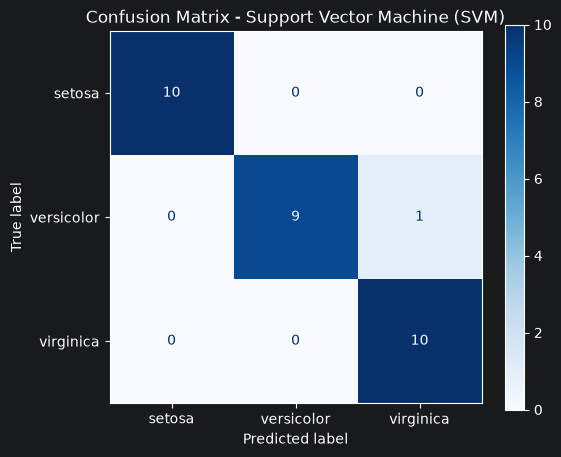

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=iris.target_names)
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Confusion Matrix - Support Vector Machine (SVM)")
plt.grid(False)
plt.show()

### 10. Visualizing 2D Decision Boundary with Support Vectors

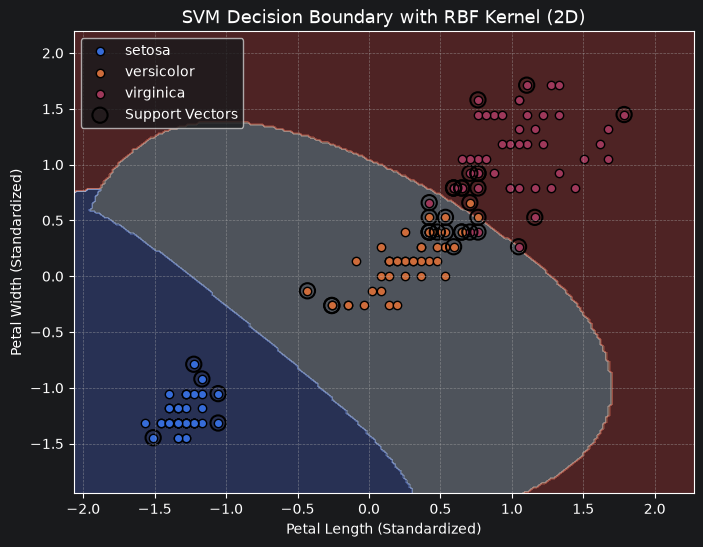

In [10]:
# Train a 2D SVM on Petal Length & Petal Width for visualization
X_2d = df[['petal length (cm)', 'petal width (cm)']].values
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

svm_2d = SVC(kernel="rbf", random_state=42)
svm_2d.fit(X_2d_scaled, y)

x_min, x_max = X_2d_scaled[:, 0].min() - 0.5, X_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_2d_scaled[:, 1].min() - 0.5, X_2d_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

for class_idx, species in enumerate(iris.target_names):
    plt.scatter(
        X_2d_scaled[y == class_idx, 0],
        X_2d_scaled[y == class_idx, 1],
        label=species,
        edgecolor="k"
    )

# Highlight Support Vectors
sv = svm_2d.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=120, facecolors='none', edgecolors='k', lw=1.5, label="Support Vectors")

plt.title("SVM Decision Boundary with RBF Kernel (2D)", fontsize=13)
plt.xlabel("Petal Length (Standardized)")
plt.ylabel("Petal Width (Standardized)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()